In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [3]:
df=pd.read_csv('../Datasets/Fashion_Trends.csv')
df

,Brand,Description,Product_ID,Discount_Price,Original_Price,Gender,Category,Discounted_amount,Discount_Percentage,Product_Name,Price_Segment,Discount_Tier
0,performax,Typographic Print Track Pants with Insert Pockets,441136763008,974,1299,Men,Activewear,325,25.02,Track Pants,Mid (₹500–₹1499),Moderate (20-40%)
1,performax,Low-Top Lace-Up Sports Shoes,450137679013,1499,1499,Men,Activewear,0,0.00,Sports Shoes,Mid (₹500–₹1499),No Discount
2,teamspirit,Colorblock Crew-Neck T-shirt,441133214008,461,549,Men,Activewear,88,16.03,Crew-Neck T-shirt,Mid (₹500–₹1499),Light (10-20%)
3,performax,Camouflage Print Joggers with Insert Pockets,441134776020,1189,1699,Men,Activewear,510,30.02,Print Joggers,Premium (₹1500–₹3999),Moderate (20-40%)
4,teamspirit,Reflective Colourblock Crew-Neck T-shirt,441136539020,425,599,Men,Activewear,174,29.05,Crew-Neck T-shirt,Mid (₹500–₹1499),Moderate (20-40%)
...,...,...,...,...,...,...,...,...,...,...,...,...
31577,ajio,Printed Top with Raglan Sleeves,460328028004,1299,1299,Women,Westernwear,0,0.00,Printed Top,Mid (₹500–₹1499),No Discount
31578,ajio,Striped Cropped Pants with Belt,460328036004,2099,2099,Women,Westernwear,0,0.00,Cropped Pants,Premium (₹1500–₹3999),No Discount
31579,ajio,Striped City Shorts with Belt,460328005002,1499,1499,Women,Westernwear,0,0.00,City Shorts,Mid (₹500–₹1499),No Discount
31580,ajio,Denim Jacket with Frayed Hemline,460328651009,2999,2999,Women,Westernwear,0,0.00,Denim Jacket,Premium (₹1500–₹3999),No Discount


# Data Preparation


### *Check and handle missing values


In [4]:
df.isnull().sum()


Brand                  0
Description            0
Product_ID             0
Discount_Price         0
Original_Price         0
Gender                 0
Category               0
Discounted_amount      0
Discount_Percentage    0
Product_Name           0
Price_Segment          0
Discount_Tier          0
dtype: int64

# Make sure the datatypes are correct for each column

In [5]:
df.dtypes

Brand                   object
Description             object
Product_ID               int64
Discount_Price           int64
Original_Price           int64
Gender                  object
Category                object
Discounted_amount        int64
Discount_Percentage    float64
Product_Name            object
Price_Segment           object
Discount_Tier           object
dtype: object

# Exploratory Data Analysis (EDA):

## *Frequency Distribution of Categorical Features Such as Product_Category, Product_Type, And Brand.

In [6]:
df.Brand.value_counts()

Brand
performax                3029
teamspirit               1908
dnmx                     1757
netplay                  1698
avaasa-mix-n-match       1507
                         ... 
bon-bon                     1
awb                         1
hk-colours-of-fashion       1
jadu                        1
classic-polo                1
Name: count, Length: 191, dtype: int64

In [7]:
df.Description.value_counts()

Description
Checked Slim Fit Shirt with Patch Pocket       571
Typographic Print Crew-Neck T-shirt            506
Slim Fit Shirt with Patch Pocket               326
Checked Shirt with Patch Pocket                262
Printed Straight Kurta                         261
                                              ... 
Straight Kurta & Printed Pant Set                1
Geometric Print Straight Kurta with Pompoms      1
Handblock Print Dupatta                          1
Floral Fit & Flare Kurta with Side Tie-Ups       1
Checked Wrap-Around Mini Skirt                   1
Name: count, Length: 11771, dtype: int64

In [8]:
df.Gender.value_counts()

Gender
Women    17207
Men      14375
Name: count, dtype: int64

In [9]:
df.Category.value_counts()

Category
Topwear        7110
Westernwear    6641
Footwear       6030
Ethnicwear     5265
Bottomwear     2984
Activewear     2134
Fusionwear      997
Lingerie        325
Innerwear        96
Name: count, dtype: int64

In [10]:
df.Product_Name.value_counts()

Product_Name
Crew-Neck T-shirt        2312
Straight Kurta           2126
Fit Shirt                2117
Polo T-shirt             1126
A-line Kurta              803
                         ... 
Self-Designed Shirt         1
fit Shirt                   1
Heavy-Wash Shirt            1
Waistcoat                   1
Polka-Dotted Trousers       1
Name: count, Length: 1799, dtype: int64

In [11]:
df.Price_Segment.value_counts()

Price_Segment
Mid (₹500–₹1499)         18237
Premium (₹1500–₹3999)     9872
Low (<₹500)               2972
Luxury (₹4000+)            501
Name: count, dtype: int64

In [12]:
df.Discount_Tier.value_counts()

Discount_Tier
Deep (>40%)           15194
 No Discount           8107
Moderate  (20-40%)     6660
Light (10-20%)         1621
Name: count, dtype: int64

## *Distribution Of Numerical Features.

In [13]:
df.describe()

,Product_ID,Discount_Price,Original_Price,Discounted_amount,Discount_Percentage
count,3.158200e+04,31582.000000,31582.000000,31582.000000,31582.000000
mean,4.439001e+11,929.759832,1418.094769,488.334938,32.979031
std,5.715579e+09,727.207471,945.684511,544.062245,24.667178
min,4.200088e+11,75.000000,149.000000,0.000000,0.000000
25%,4.411142e+11,479.000000,799.000000,0.000000,0.000000
50%,4.411360e+11,735.000000,1299.000000,356.000000,35.040000
75%,4.501273e+11,1199.000000,1799.000000,749.000000,50.930000
max,4.608526e+11,16999.000000,19999.000000,11999.000000,85.010000


### The dataset contains 31,582 products, with an average original price of ₹1,418 and an average discounted price of ₹930. The average discount is 32.98%, with original prices ranging from ₹149 to ₹19,999 and discounted prices from ₹75 to ₹16,999.

## *Identify Outliers In Price And Discount {Visulization}.

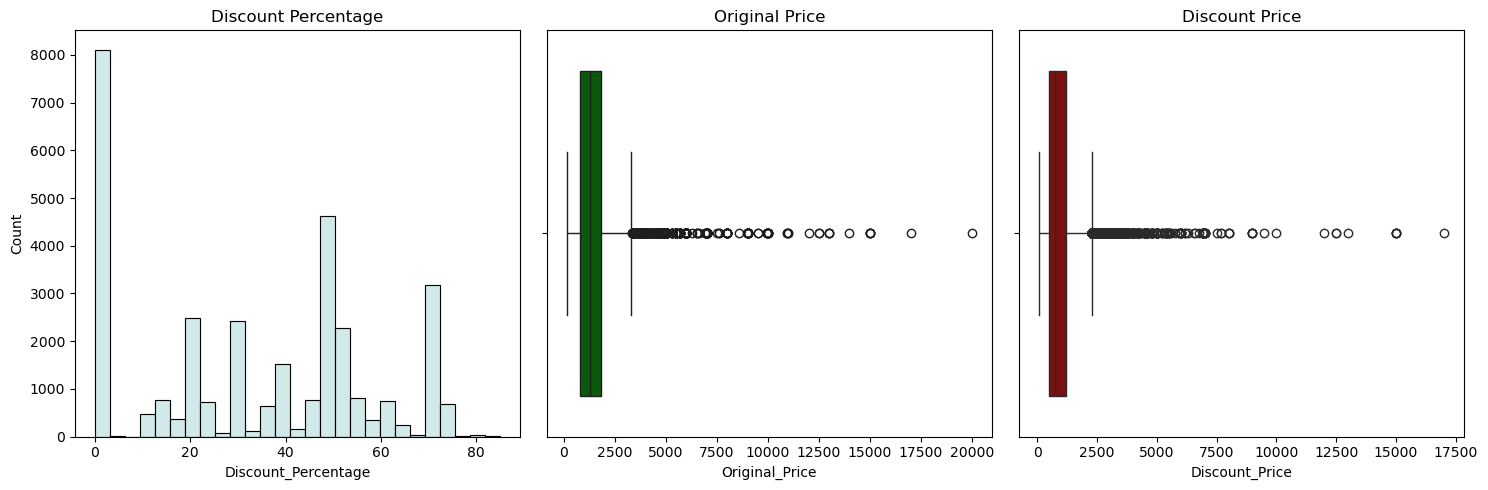

In [14]:
 

plt.figure(figsize=(15, 5))

# 1st Plot: Histogram
plt.subplot(1, 3, 1)
sb.histplot(df.Discount_Percentage, color=sb.color_palette("ch:start=.2,rot=-.3")[0])
plt.title("Discount Percentage")

# 2nd Plot: Boxplot
plt.subplot(1, 3, 2)
sb.boxplot(x=df.Original_Price, color='darkgreen')
plt.title("Original Price")

# 3rd Plot: Boxplot
plt.subplot(1, 3, 3)
sb.boxplot(x=df.Discount_Price, color='darkred')
plt.title("Discount Price")

plt.tight_layout()
plt.show()

           

# Outcome:

### - Fashion products have an average discount of 32.98%, with the highest discount reaching 85.01%.
### - The median original price is ₹1,299, which drops to ₹735 after discounts.
### - A few products have unusually high prices, indicating a wide variation in product pricing.

# Brand & Category Analysis:

### *Which Brands Have The Most Products

In [15]:
df.Brand.value_counts().nlargest(5)

Brand
performax             3029
teamspirit            1908
dnmx                  1757
netplay               1698
avaasa-mix-n-match    1507
Name: count, dtype: int64

## *Which Categories Dominate Overall In Each Price Segment

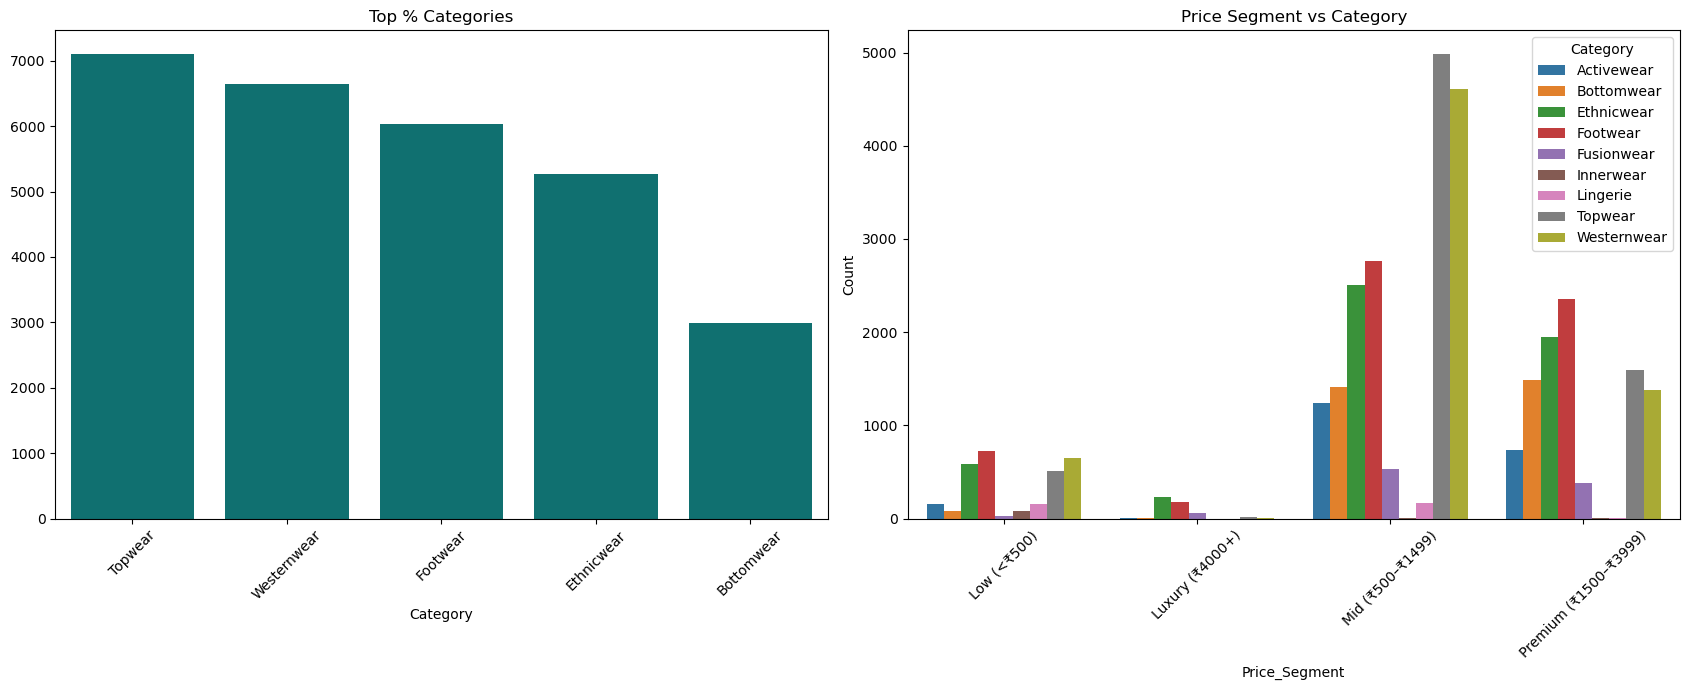

In [16]:

plt.figure(figsize=(17, 7))

# Plot 1: Top 5 Categories
plt.subplot(1, 2, 1)
a = df.Category.value_counts().nlargest(5)
sb.barplot(x=a.index, y=a.values,color='teal')
plt.title("Top % Categories")
plt.xticks(rotation=45)

# Plot 2: Price Segment Vs Category
plt.subplot(1,2,2)
c = df.groupby(['Price_Segment', 'Category']).size().reset_index(name='Count')
sb.barplot(data=c, x='Price_Segment', y='Count', hue='Category')
plt.title("Price Segment vs Category")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()






# Outcome:

### -Topwear Has The Highest Number Of Products (7,110) Followed by Westernwear (6,641) and Footwear (6,030).
### -The Mid-Price Segment (₹500–₹1,499) Contains The Most Products (18,237) With Topwear Being Its largest Category At 4,989 Products. 

# Product Type Analysis:

### *Which Product Type (T-shirts, Jeans, Sarees, Shoes) are Most Common

In [17]:
df['Product_Name'].value_counts()

Product_Name
Crew-Neck T-shirt        2312
Straight Kurta           2126
Fit Shirt                2117
Polo T-shirt             1126
A-line Kurta              803
                         ... 
Self-Designed Shirt         1
fit Shirt                   1
Heavy-Wash Shirt            1
Waistcoat                   1
Polka-Dotted Trousers       1
Name: count, Length: 1799, dtype: int64

### *Compare Product Type Distribution Across Genders And Top Product Type Within Each Category

C:\Users\Lokesh\AppData\Local\Temp\ipykernel_6048\740317737.py:16: UserWarning: 
The palette list has fewer values (6) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sb.barplot(data=g, x='Product_Name', y='Count', hue='Category',palette=['#8B0000', '#B22222', '#CC5500', '#E67E00', '#B8860B', '#DAA520'])


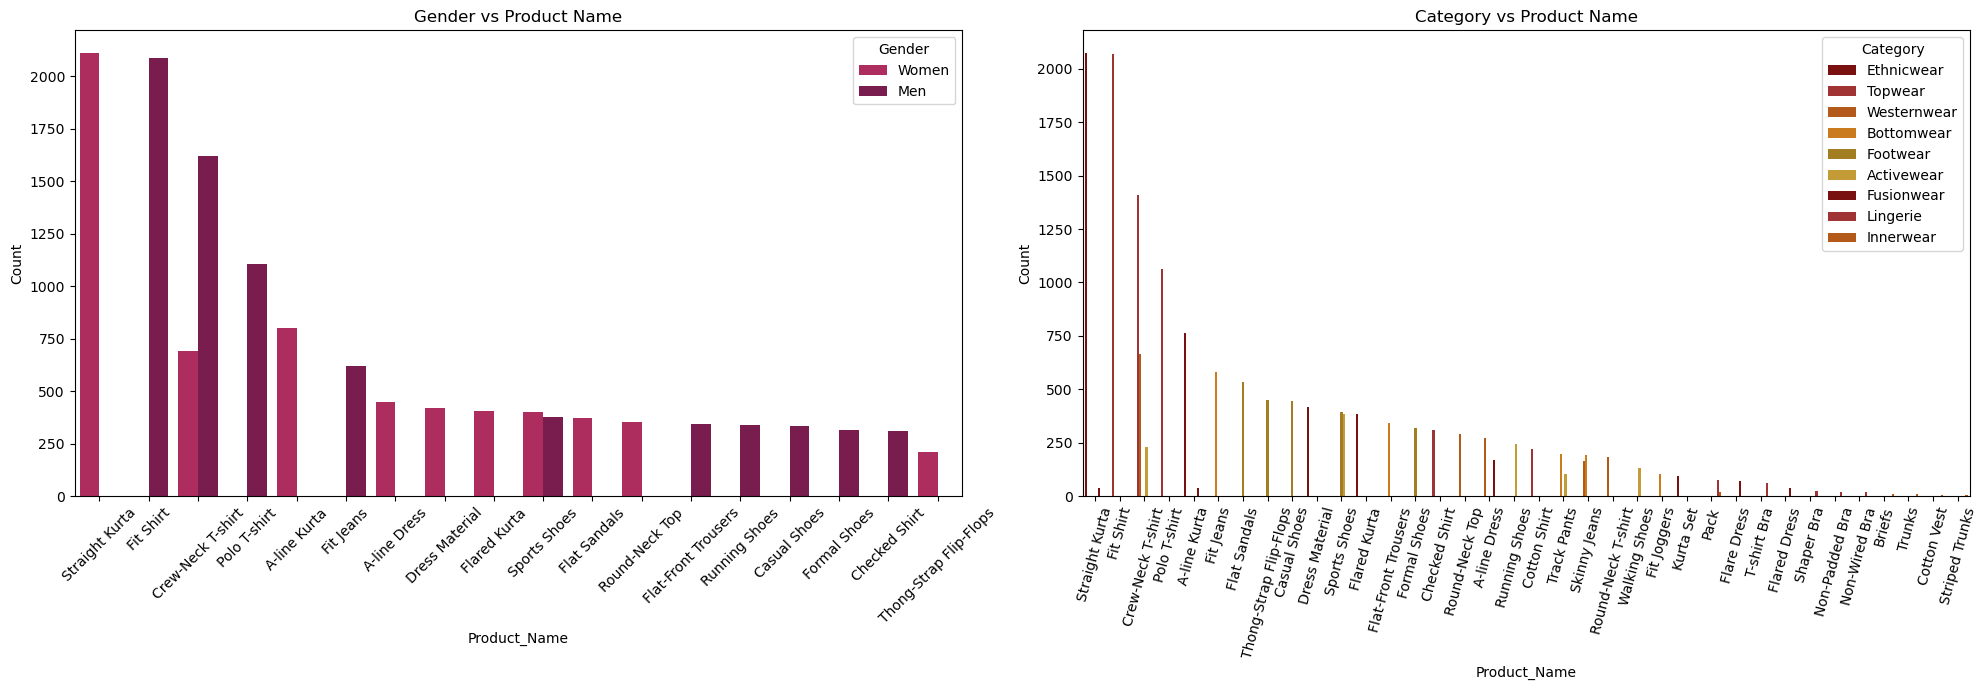

In [20]:

plt.figure(figsize=(20, 7))


# 1st Plot: Gender vs Product Name
plt.subplot(1, 2, 1)
p = df.groupby(['Gender', 'Product_Name']).size().reset_index(name='Count').sort_values('Count', ascending=False)
p = p.groupby('Gender').head(10)
sb.barplot(data=p, x='Product_Name', y='Count', hue='Gender',palette=['#C2185B', '#880E4F'])
plt.xticks(rotation=45)
plt.title("Gender vs Product Name")

# 2nd Plot: Category vs Product Name
plt.subplot(1, 2, 2)
g = df.groupby(['Category', 'Product_Name']).size().reset_index(name='Count').sort_values('Count', ascending=False)
g = g.groupby('Category').head(5)
sb.barplot(data=g, x='Product_Name', y='Count', hue='Category',palette=['#8B0000', '#B22222', '#CC5500', '#E67E00', '#B8860B', '#DAA520'])
plt.xticks(rotation=75)
plt.title("Category vs Product Name")
plt.tight_layout()
plt.show()



# Outcome:

### -Women's Products (17,207) Are More Represented Than Men's Products (14,375), Indicating a Higher Product Count In Women's Fashion.
### -Straight Kurta (2,113) And Fit Shirt (2,087) are Leading Product Types, Helping Identify Popular Items For Inventory Planning

# Discount Analysis:

### *How Many Products Fall Into Each Discount Tier

In [22]:
df.groupby('Discount_Tier').size()

Discount_Tier
 No Discount           8107
Deep (>40%)           15194
Light (10-20%)         1621
Moderate  (20-40%)     6660
dtype: int64

### 1. Which Product Types Get The Highest Average Discount
### 2. Which Categories Rely Most On Heavy Discounts
### 3. Are Higher-Priced Products More Likely To Have Higher discounts 

C:\Users\Lokesh\AppData\Local\Temp\ipykernel_15280\2717210211.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=d.index, y=d.values,palette=['#8B0000', '#CC0000', '#FF4500', '#FFD700', '#DAA520'])
C:\Users\Lokesh\AppData\Local\Temp\ipykernel_15280\2717210211.py:6: UserWarning: 
The palette list has fewer values (5) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sb.barplot(x=d.index, y=d.values,palette=['#8B0000', '#CC0000', '#FF4500', '#FFD700', '#DAA520'])


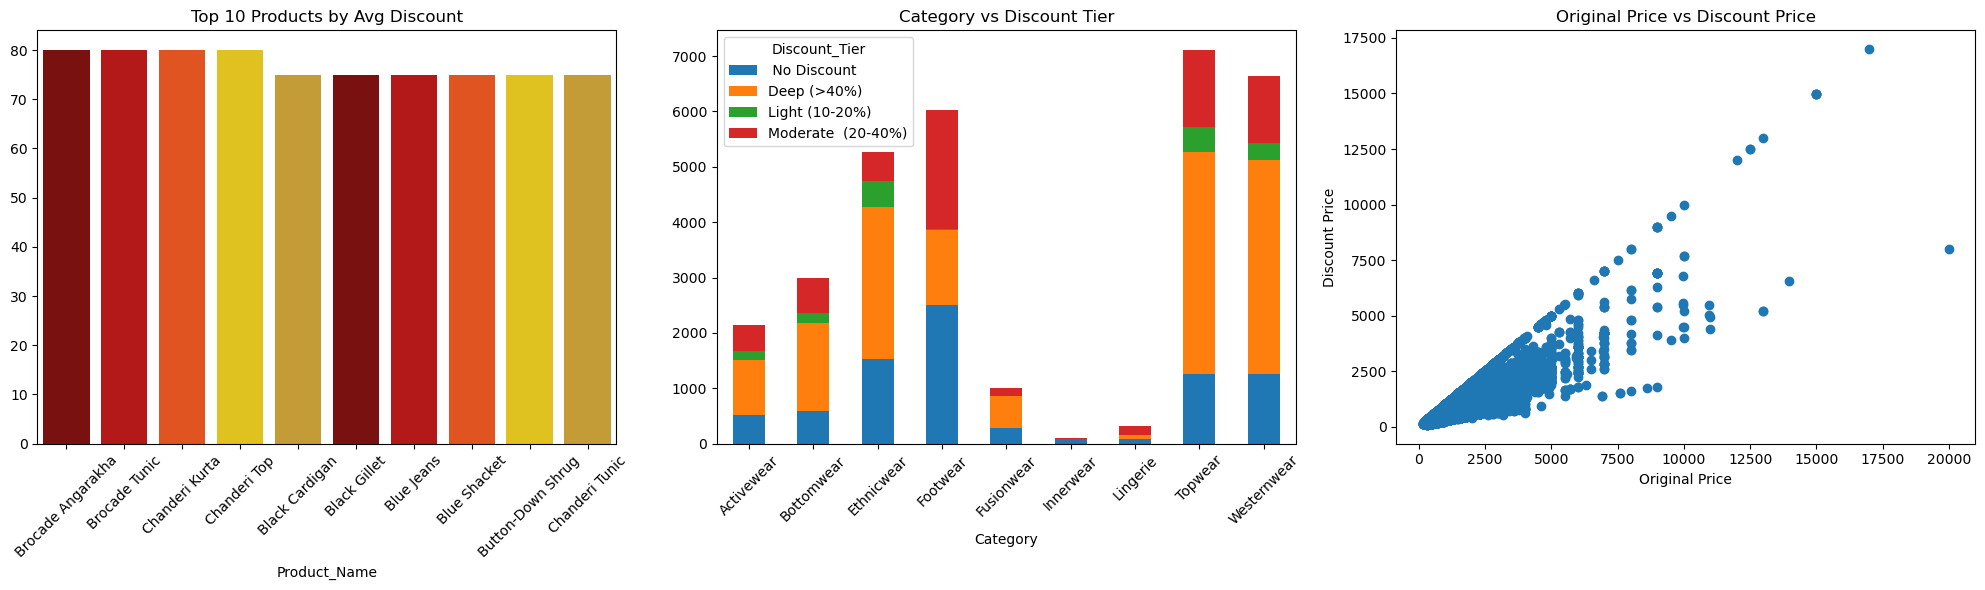

In [33]:
plt.figure(figsize=(20, 6))

# 1st Plot: Top 10 Products by Average Discount
plt.subplot(1, 3, 1)
d = df.groupby('Product_Name')['Discount_Percentage'].mean().nlargest(10)
sb.barplot(x=d.index, y=d.values,palette=['#8B0000', '#CC0000', '#FF4500', '#FFD700', '#DAA520'])
plt.xticks(rotation=45)
plt.title("Top 10 Products by Avg Discount")

# 2nd Plot: Category vs Discount Tier
plt.subplot(1, 3, 2)
s = df.groupby(['Category', 'Discount_Tier']).size().unstack(fill_value=0)
s.plot(kind='bar', stacked=True, ax=plt.gca())
plt.title("Category vs Discount Tier")
plt.xticks(rotation=45)

# 3rd Plot: Original Price vs Discount Price
plt.subplot(1, 3, 3)
plt.scatter(df.Original_Price, df.Discount_Price)
plt.title("Original Price vs Discount Price")
plt.xlabel("Original Price")
plt.ylabel("Discount Price")
plt.tight_layout()
plt.show()

# Outcome:

### -Brocade Angarakha And Brocade Tunic have Average Discounts Of Around 80% Followed by Chanderi Kurti And Chanderi Top at 79.99%.
### -Around 15,194 Products (48.11%) have Discounts Above 40% While 8,107 Products (25.67%) Have No Discount.
### -Original And Discounted Prices Show a Strong Positive Correlation Of 0.82 Meaning Higher-Priced Products Generally Have Higher Discounted Prices Too.

# Gender-Based Preferences:

### Which Categories And Product Types Dominate For Men Vs Women Vs Kids

In [27]:
 df.groupby(['Gender','Category']).size()

Gender  Category   
Men     Activewear     1170
        Bottomwear     2984
        Footwear       3015
        Innerwear        96
        Topwear        7110
Women   Activewear      964
        Ethnicwear     5265
        Footwear       3015
        Fusionwear      997
        Lingerie        325
        Westernwear    6641
dtype: int64

### Gender-Wise Average Discount %

C:\Users\Lokesh\AppData\Local\Temp\ipykernel_15280\1379045964.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=g.index,y=g.values, palette = ['#ADD8E6', '#FFB6C1'])


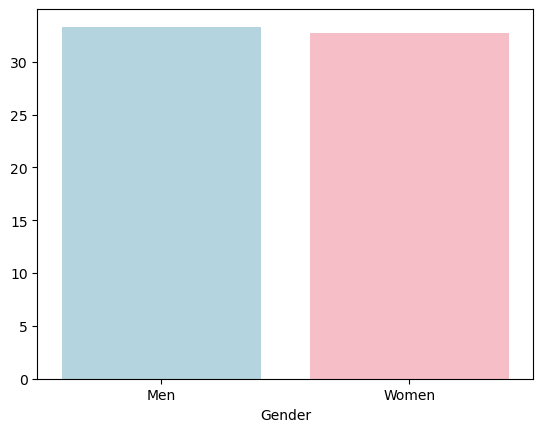

In [32]:
g=df.groupby('Gender')['Discount_Percentage'].mean()
sb.barplot(x=g.index,y=g.values, palette = ['#ADD8E6', '#FFB6C1'])
plt.show()

### -Men's Products Have An Average Discount of 33.3% While Women's Products Have 32.6% Showing That Men's Products Receive Slightly Higher Average Discounts.

# Price Segments Analysis:

### 1. Distribution Of Products Across Budget, Mid, Premium, Luxury.
### 2. Compare Brand Positioning (Budget Vs Premium Brands).

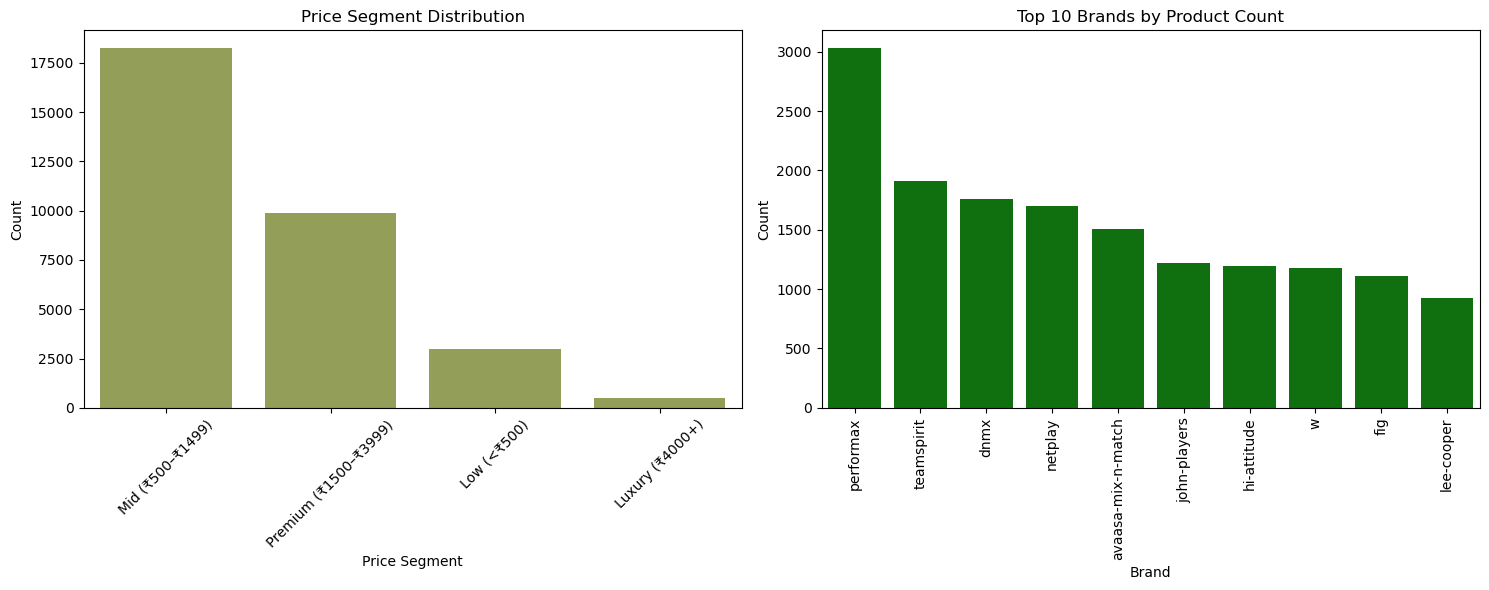

In [29]:
plt.figure(figsize=(15, 6))

# 1st Plot: Price Segment Distribution
plt.subplot(1, 2, 1)
d = df['Price_Segment'].value_counts()
sb.barplot(x=d.index, y=d.values, color='#9BAA4D')
plt.title("Price Segment Distribution")
plt.xlabel("Price Segment")
plt.ylabel("Count")
plt.xticks(rotation=45)

# 2nd Plot: Top 10 Brands by Product Count
plt.subplot(1, 2, 2)
b = df.groupby(['Brand', 'Price_Segment']).size().reset_index(name='count')
b = b.groupby('Brand')['count'].sum().nlargest(10)
sb.barplot(x=b.index, y=b.values,color='green')
plt.title("Top 10 Brands by Product Count")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


# Outcome

### -The Mid-Price Segment Has The Highest Product Count at 18,237 (57.7%) While The Luxury Segment Has Only 501 Products (1.59%).
### -Performax Leaders With 3,029 Products, Followed By Teamspirit With 1,908 And DNMX With 1,757 Products.

# Which Categories Dominate In Each Segment

In [30]:
pd.crosstab(df['Category'],df['Price_Segment'])

Price_Segment,Low (<₹500),Luxury (₹4000+),Mid (₹500–₹1499),Premium (₹1500–₹3999)
Category,,,,
Activewear,156,9,1237,732
Bottomwear,79,3,1414,1488
Ethnicwear,588,227,2506,1944
Footwear,725,182,2766,2357
Fusionwear,25,61,532,379
Innerwear,83,0,11,2
Lingerie,153,0,171,1
Topwear,515,15,4989,1591
Westernwear,648,4,4611,1378



### Topwear (4,989) and Westernwear (4,611) have the highest product counts in the Mid-price segment. Footwear leads the Premium segment with 2,357 products, while Ethnicwear has the most Luxury products, with 227 items.

